# Partial-Spoof Source Tracing — Notebook 2: Test Evaluation
(Localization F1 + Open-Set Source Identification)

Loads **both** HuBERT-based checkpoints trained in Notebook 1 (`attribution_model.pt`,
`localization_model.pt`) and evaluates each on the test split (A07–A19,
attacks never seen during training) with the metric that's actually
well-defined for that task:

| Task | Metric | Why it works on unseen attacks |
|---|---|---|
| **Localization** (real/fake per frame) | **Segment-level F1** (same TP/FP/TN/FN as Figure 3) | Real/fake is binary and attack-agnostic -- the model never needs to name *which* algorithm, so unseen algorithms are no different from seen ones for this task. |
| **Source identification** (which generator) | **Verification EER + accuracy**, *not* classification accuracy | Classification accuracy needs a fixed output slot per class -- undefined for A07–A19. Reframed as "are these two spoofed segments from the *same* generator or different generators," it becomes a same/different judgment that works on unseen classes, exactly like speaker-verification EER works on unseen speakers. |
| (bonus) Open-set clustering (NMI/ARI/purity) | kept from before as a complementary view | Same idea as verification, but grouping instead of pairwise. |

## Why one combined streaming pass
Both tasks need a wav2vec2 forward pass over the same test audio. Running it
twice would double your ~50 minute test-set runtime for no reason, so this
notebook does **one** streaming pass: for each batch, run wav2vec2 once, then
derive (a) the cropped-segment attribution embedding and (b) the full-sequence
localization prediction from the same hidden states. Nothing framewise is
cached to disk -- only the small final artifacts (embeddings + running
TP/FP/TN/FN counts) are persisted, same storage-safety approach as before.
Resumable via periodic checkpointing, same as before.

## Before running
1. Add Notebook 1's output (containing both `.pt` files) as a Kaggle Dataset
   input.
2. Edit the paths in the **Config** cell: `TEST_METADATA_CSV`,
   `TEST_AUDIO_DIR`, `ATTRIBUTION_CHECKPOINT_PATH`, `LOCALIZATION_CHECKPOINT_PATH`.


## 0. Install & imports

In [1]:
!pip install -q transformers librosa soundfile


## 1. Config

In [2]:
# ============================================================
# IMPORTS
# ============================================================

import os
import json
import math
import time
import random

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

import soundfile as sf
import librosa
import os
import json
import math
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import soundfile as sf
import librosa

from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

print("torch:", torch.__version__, "| cuda available:", torch.cuda.is_available())

from sklearn.metrics import roc_curve
from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score
from sklearn.preprocessing import LabelEncoder
from sklearn.cluster import KMeans

print("torch:", torch.__version__, "| cuda available:", torch.cuda.is_available())


# ============================================================
# DATA / CHECKPOINT PATHS
# ============================================================

TEST_METADATA_CSV = "/kaggle/input/datasets/hasinivn/test-final-data/partialspoof_test_dataset/metadata.csv"
TEST_AUDIO_DIR    = "/kaggle/input/datasets/hasinivn/test-final-data/partialspoof_test_dataset/audio"

ATTRIBUTION_CHECKPOINT_PATH = "/kaggle/input/datasets/speech7lab/models-final-mfcc/attribution_model_rawformer_wavelet_mfcc.pt"
LOCALIZATION_CHECKPOINT_PATH = "/kaggle/input/datasets/speech7lab/models-final-mfcc/localization_model_mfcc.pt"

AUDIO_EXT = ".flac"


# ============================================================
# WORKING DIRECTORIES
# ============================================================

WORK_DIR = "/kaggle/working"

RESULTS_DIR = os.path.join(WORK_DIR, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

EMBEDDINGS_PATH = os.path.join(RESULTS_DIR, "test_embeddings.npy")
ATTACKS_PATH = os.path.join(RESULTS_DIR, "test_attacks.json")
LOC_COUNTS_PATH = os.path.join(RESULTS_DIR, "loc_counts.json")


# ============================================================
# MFCC PARAMETERS
# ============================================================
# Placeholders -- overwritten from the attribution checkpoint's saved config
# right after loading it below, so extraction matches Notebook 1 exactly.

FEATURE_DIM = None
N_MFCC = None
USE_DELTA = None
NORMALIZE_MFCC = None
MFCC_N_FFT = None
MFCC_HOP_LENGTH = None   # used for all sample-index <-> frame-index conversions


STREAM_BATCH_SIZE = 8
CKPT_EVERY_ROWS = 5000
SAMPLE_RATE = 16000

N_MFCC = 40                 # number of MFCC coefficients
MFCC_N_FFT = 400             # 25ms window @ 16kHz
MFCC_HOP_LENGTH = 320         # ~20ms per frame @ 16kHz (kept equal to old wav2vec stride
                              # so sample_to_frame()/clip_segment() need no changes)
USE_DELTA = True             # append delta + delta-delta -> 3x the coefficients
NORMALIZE_MFCC = True         # per-utterance mean/var normalization (CMVN)

FEATURE_DIM = N_MFCC * 3 if USE_DELTA else N_MFCC   # everything downstream reads this

FEATURE_EXTRACTION_BATCH_SIZE = 32   # just a progress-logging chunk size now (no GPU batching needed)
FEATURE_DTYPE = "float16"      # halves disk usage for the cache

# ----------------------------- ATTRIBUTION HEAD ------------------------------
KNOWN_ATTACKS = ["A01", "A02", "A03", "A04", "A05", "A06"]   # train/val label set
NUM_KNOWN_CLASSES = len(KNOWN_ATTACKS)

EMBED_DIM = 256
USE_AAM = True          # AAM-Softmax (margin) vs plain softmax classifier
AAM_MARGIN = 0.2
AAM_SCALE = 30.0

ATTR_BATCH_SIZE = 64
ATTR_EPOCHS = 40
ATTR_LR = 1e-3
ATTR_WEIGHT_DECAY = 1e-4
ATTR_EARLY_STOP_PATIENCE = 8

MIN_SEGMENT_FRAMES = 2 
# ============================================================
# VERIFICATION SETTINGS
# ============================================================

N_POSITIVE_TRIALS = 20000
N_NEGATIVE_TRIALS = 20000

TEST_NUM_CLUSTERS = None


# ============================================================
# RANDOM SEED
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", DEVICE)

torch: 2.10.0+cu128 | cuda available: True
torch: 2.10.0+cu128 | cuda available: True
Device: cuda


## 3. Model definitions (must match Notebook 1 exactly to load the checkpoints)

In [3]:
def sample_to_frame(sample_idx: int, stride: int = MFCC_HOP_LENGTH) -> int:
    """Approximate conversion from a raw sample index to an MFCC frame index
    (hop ~320 samples/frame @ 16kHz). Accurate to +/- 1-2 frames."""
    return int(sample_idx // stride)

class AttributionDataset(Dataset):
    """Returns (spoof_segment_features [T', D], label_idx, attack_str).
    `cache_dir` must be the cache directory for THIS split specifically."""

    def __init__(self, metadata_csv: str, cache_dir: str, label_encoder: dict = None):
        self.cache_dir = cache_dir
        self.df = pd.read_csv(metadata_csv).reset_index(drop=True)
        exists_mask = self.df["file"].apply(
            lambda f: os.path.exists(os.path.join(cache_dir, f.replace(AUDIO_EXT, ".npy")))
        )
        dropped = (~exists_mask).sum()
        if dropped:
            print(f"[AttributionDataset:{cache_dir}] dropping {dropped} rows with no cached features")
        self.df = self.df[exists_mask].reset_index(drop=True)

        if label_encoder is None:
            label_encoder = {a: i for i, a in enumerate(KNOWN_ATTACKS)}
        self.label_encoder = label_encoder

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        feat = _load_cached(self.cache_dir, row["file"])
        num_frames = feat.shape[0]

        f_start = sample_to_frame(int(row["start"]))
        f_end = sample_to_frame(int(row["end"]))
        f_start, f_end = clip_segment(f_start, f_end, num_frames, min_len=MIN_SEGMENT_FRAMES)

        segment = feat[f_start:f_end]
        label = self.label_encoder.get(row["attack"], -1)
        return torch.from_numpy(segment), label, row["attack"]


def attribution_collate(batch):
    segments, labels, attacks = zip(*batch)
    lengths = [s.shape[0] for s in segments]
    max_len = max(lengths)
    dim = segments[0].shape[1]

    padded = torch.zeros(len(segments), max_len, dim)
    mask = torch.zeros(len(segments), max_len, dtype=torch.bool)
    for i, s in enumerate(segments):
        padded[i, :s.shape[0]] = s
        mask[i, :s.shape[0]] = True

    labels = torch.tensor(labels, dtype=torch.long)
    return padded, mask, labels, list(attacks)

def clip_segment(frame_start: int, frame_end: int, num_frames: int, min_len: int = 1):
    """Clip a [start, end) frame range to valid bounds, guaranteeing >= min_len frames."""
    frame_start = max(0, min(frame_start, num_frames - 1))
    frame_end = max(frame_start + min_len, min(frame_end, num_frames))
    frame_end = min(frame_end, num_frames)
    if frame_end <= frame_start:
        frame_start = max(0, num_frames - min_len)
        frame_end = num_frames
    return frame_start, frame_end

def load_audio(path: str, target_sr: int = SAMPLE_RATE) -> np.ndarray:
    wav, sr = sf.read(path, dtype="float32")
    if wav.ndim > 1:
        wav = wav.mean(axis=1)
    if sr != target_sr:
        wav = librosa.resample(wav, orig_sr=sr, target_sr=target_sr)
    return wav


def extract_mfcc_features(wav: np.ndarray) -> np.ndarray:
    """Returns (T, FEATURE_DIM) array: MFCC (+ delta + delta-delta if enabled),
    optionally per-utterance mean/var normalized."""
    mfcc = librosa.feature.mfcc(
        y=wav, sr=SAMPLE_RATE, n_mfcc=N_MFCC,
        n_fft=MFCC_N_FFT, hop_length=MFCC_HOP_LENGTH,
    )  # (n_mfcc, T)

    if USE_DELTA:
        delta1 = librosa.feature.delta(mfcc, order=1)
        delta2 = librosa.feature.delta(mfcc, order=2)
        feat = np.concatenate([mfcc, delta1, delta2], axis=0)  # (FEATURE_DIM, T)
    else:
        feat = mfcc

    feat = feat.T  # (T, FEATURE_DIM)

    if NORMALIZE_MFCC:
        mean = feat.mean(axis=0, keepdims=True)
        std = feat.std(axis=0, keepdims=True)
        feat = (feat - mean) / (std + 1e-5)

    return feat.astype(FEATURE_DTYPE)


def process_split(metadata_csv, audio_dir, cache_dir, split_name):
    if not os.path.exists(metadata_csv):
        print(f"[skip] {split_name}: metadata not found at {metadata_csv}")
        return
    df = pd.read_csv(metadata_csv)

    todo = []
    for fname in df["file"]:
        out_path = os.path.join(cache_dir, fname.replace(AUDIO_EXT, ".npy"))
        if not os.path.exists(out_path):
            todo.append(fname)
    print(f"[{split_name}] {len(todo)}/{len(df)} files need feature extraction (cache: {cache_dir}).")

    t0 = time.time()
    for i, fname in enumerate(todo):
        path = os.path.join(audio_dir, fname)
        if not os.path.exists(path):
            print(f"  [warn] missing audio file: {path}")
            continue

        wav = load_audio(path)
        feat = extract_mfcc_features(wav)

        out_path = os.path.join(cache_dir, fname.replace(AUDIO_EXT, ".npy"))
        np.save(out_path, feat)

        if i % (FEATURE_EXTRACTION_BATCH_SIZE * 20) == 0 and i > 0:
            elapsed = time.time() - t0
            rate = i / max(elapsed, 1e-6)
            eta = (len(todo) - i) / max(rate, 1e-6)
            print(f"  [{split_name}] {i}/{len(todo)} done | {rate:.1f} files/s | ETA {eta/60:.1f} min")

    print(f"[{split_name}] feature extraction complete.")

def _load_cached(cache_dir: str, fname: str) -> np.ndarray:
    path = os.path.join(cache_dir, fname.replace(AUDIO_EXT, ".npy"))
    return np.load(path).astype(np.float32)


class Conv2DBlockFeature(nn.Module):
    def __init__(
        self,
        in_channels: int,
        out_channels: int,
        is_first_block: bool = False,
        pool_size=(1, 2),
    ):
        super().__init__()

        self.normalizer = None

        if not is_first_block:
            self.normalizer = nn.Sequential(
                nn.BatchNorm2d(in_channels),
                nn.SELU(inplace=True),
            )

        self.layers = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=(2, 5),
                padding=(1, 2),
            ),
            nn.BatchNorm2d(out_channels),
            nn.SELU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=(2, 3),
                padding=(0, 1),
            ),
        )

        self.downsampler = None

        if in_channels != out_channels:
            self.downsampler = nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=(1, 3),
                padding=(0, 1),
            )

        # Much smaller temporal pooling
        self.pooling = nn.MaxPool2d(
            kernel_size=pool_size,
            stride=pool_size,
            ceil_mode=True,
        )

    def forward(self, x):

        identity = x

        if self.downsampler is not None:
            identity = self.downsampler(identity)

        if self.normalizer is not None:
            x = self.normalizer(x)

        x = self.layers(x) + identity

        x = self.pooling(x)

        return x

class FeatureFrontend(nn.Module):

    def __init__(self, feature_dim):
        super().__init__()

        self.conv_blocks = nn.Sequential(

            Conv2DBlockFeature(
                in_channels=1,
                out_channels=32,
                is_first_block=True,
                pool_size=(1, 2),
            ),

            Conv2DBlockFeature(
                in_channels=32,
                out_channels=32,
                pool_size=(1, 2),
            ),

            Conv2DBlockFeature(
                in_channels=32,
                out_channels=64,
                pool_size=(1, 2),
            ),

            Conv2DBlockFeature(
                in_channels=64,
                out_channels=64,
                pool_size=(1, 2),
            ),
        )

    def forward(self, x):

        # x: [B, T, D]

        # [B, T, D]
        # → [B, D, T]
        x = x.transpose(1, 2)

        # → [B, 1, D, T]
        x = x.unsqueeze(1)

        x = self.conv_blocks(x)

        return x

class MaskedSequencePooling(nn.Module):
    """
    Input:
        x    : [B, S, C]
        mask : [B, S]

    Output:
        [B, C]
    """

    def __init__(self, d_model):
        super().__init__()

        self.linear = nn.Linear(d_model, 1)

    def forward(self, x, mask=None):

        # [B, S, C] → [B, S, 1]
        w = self.linear(x)

        if mask is not None:

            # Padding positions get -inf
            w = w.masked_fill(
                ~mask.unsqueeze(-1),
                float("-inf")
            )

        # Attention weights over sequence
        w = F.softmax(w, dim=1)

        # Weighted sum
        out = torch.sum(w * x, dim=1)

        return out

class WaveletFANFeatureMap(nn.Module):
    """
    Bump Wavelet FAN (SAFE)
    """
    def __init__(self, d_head, d_phi=None):
        super().__init__()
        if d_phi is None:
            d_phi = d_head
        assert d_phi % 2 == 0

        self.linear_p = nn.Linear(d_head, d_phi // 2)
        self.linear_g = nn.Linear(d_head, d_phi // 2)
        self.act = nn.GELU()

        self.log_scale = nn.Parameter(torch.zeros(1))
        self.gate = nn.Parameter(torch.randn(1))

    def forward(self, x):
        z = self.linear_p(x)
        g = self.act(self.linear_g(x))

        s = torch.exp(self.log_scale) + 1e-4  # slightly larger eps
        u = z / s

        # ---- Bump wavelet (SAFE) ----
        wavelet = torch.zeros_like(u)
        mask = (u.abs() < 1.0)
        
        wavelet[mask] = torch.exp(-1.0 / (1.0 - u[mask]**2))
        wavelet = wavelet / (wavelet.std(dim=-1, keepdim=True) + 1e-5)




        gate = torch.sigmoid(self.gate)

        return torch.cat([
            gate * wavelet,
            (1 - gate) * g
        ], dim=-1)

# -------------------------------
# Multi-Head Wavelet-FAN
# -------------------------------
class MultiHeadWaveletFAN(nn.Module):
    def __init__(self, d_model, n_head=8, d_head=None):
        super().__init__()
        self.n_head = n_head
        if d_head is None:
            assert d_model % n_head == 0
            d_head = d_model // n_head
        self.d_head = d_head

        self.heads = nn.ModuleList([
            WaveletFANFeatureMap(d_head)
            for _ in range(n_head)
        ])

        self.out_proj = nn.Linear(n_head * d_head, d_model)

    def forward(self, x):
        B, S, D = x.shape
        x = x.view(B, S, self.n_head, self.d_head).permute(0, 2, 1, 3)

        head_outs = []
        for h in range(self.n_head):
            head_outs.append(self.heads[h](x[:, h]))

        out = torch.cat(head_outs, dim=-1)
        return self.out_proj(out)

class LayerNorm(nn.Module):
    def __init__(self, d_model, eps=1e-12):
        super().__init__()
        self.gamma = nn.Parameter(torch.ones(d_model))
        self.beta = nn.Parameter(torch.zeros(d_model))
        self.eps = eps

    def forward(self, x):
        mean = x.mean(-1, keepdim=True)
        var = x.var(-1, unbiased=False, keepdim=True)
        xhat = (x - mean) / torch.sqrt(var + self.eps)
        return self.gamma * xhat + self.beta
class FFN(nn.Module):
    def __init__(self, d_model, ffn_hidden, drop_prob=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, ffn_hidden),
            nn.ReLU(),
            nn.Dropout(drop_prob),
            nn.Linear(ffn_hidden, d_model),
        )

    def forward(self, x):
        return self.net(x)
# -------------------------------
# Wavelet Transformer Encoder Layer
# -------------------------------
class TransformerEncoderLayerWaveletFAN(nn.Module):
    def __init__(self, d_model=64, n_head=8, ffn_hidden=2048, drop_prob=0.1):
        super().__init__()

        self.attn = MultiHeadWaveletFAN(d_model, n_head)
        self.dropout1 = nn.Dropout(drop_prob)
        self.norm1 = LayerNorm(d_model)

        self.ffn = FFN(d_model, ffn_hidden, drop_prob)
        self.dropout2 = nn.Dropout(drop_prob)
        self.norm2 = LayerNorm(d_model)

    def forward(self, x):
        residual = x
        x = self.attn(x)
        x = self.dropout1(x)
        x = self.norm1(x + residual)

        residual = x
        x = self.ffn(x)
        x = self.dropout2(x)
        x = self.norm2(x + residual)
        return x

class FeatureRawformerClassifier(nn.Module):

    def __init__(
        self,
        C=64,
        n_encoder=2,
        transformer_hidden=2048,
        embedding_dim=128,
    ):
        super().__init__()

        self.encoders = nn.ModuleList([
            TransformerEncoderLayerWaveletFAN(
                d_model=C,
                n_head=8,
                ffn_hidden=transformer_hidden,
            )
            for _ in range(n_encoder)
        ])

        self.seq_pool = MaskedSequencePooling(
            d_model=C
        )

        self.embedding = nn.Sequential(
            nn.Linear(C, embedding_dim),
            nn.BatchNorm1d(embedding_dim),
        )

    def forward(self, x, mask=None):

        for encoder in self.encoders:
            x = encoder(x)

        x = self.seq_pool(x, mask)

        return self.embedding(x)

class PositionalAggregator1D(nn.Module):

    def __init__(
        self,
        max_C=64,
        max_ft=5000,
    ):
        super().__init__()

        position = torch.arange(
            max_ft
        ).float().unsqueeze(1)

        div_term = torch.exp(
            torch.arange(
                0,
                max_C,
                2
            ).float()
            *
            (-math.log(10000.0) / max_C)
        )

        encoding = torch.zeros(
            max_ft,
            max_C
        )

        encoding[:, 0::2] = torch.sin(
            position * div_term
        )

        encoding[:, 1::2] = torch.cos(
            position * div_term
        )

        self.register_buffer(
            "encoding",
            encoding
        )

    def forward(self, HFM):

        # HFM: [B, C, f, t]

        B, C, f, t = HFM.shape

        # [B, C, f, t]
        # → [B, C, f*t]
        x = HFM.flatten(
            start_dim=2
        )

        # → [B, f*t, C]
        x = x.transpose(1, 2)

        S = x.size(1)

        x = x + self.encoding[
            :S,
            :C
        ].unsqueeze(0)

        return x

class FeatureRawformerAttributionModel(nn.Module):

    def __init__(
        self,
        feature_dim=FEATURE_DIM,
        embed_dim=EMBED_DIM,
        num_classes=NUM_KNOWN_CLASSES,
        use_aam=USE_AAM,
        transformer_hidden=2048,
        n_encoder=2,
        max_sequence_length=20000,
    ):
        super().__init__()

        # ----------------------------------
        # Feature input frontend
        # ----------------------------------
        self.front_end = FeatureFrontend(
            feature_dim=feature_dim
        )

        # ----------------------------------
        # Positional aggregation
        # ----------------------------------
        self.positional_embedding = PositionalAggregator1D(
            max_C=64,
            max_ft=max_sequence_length,
        )

        # ----------------------------------
        # Wavelet-FAN Rawformer classifier
        # ----------------------------------
        self.encoder = FeatureRawformerClassifier(
            C=64,
            n_encoder=n_encoder,
            transformer_hidden=transformer_hidden,
            embedding_dim=embed_dim,
        )

        # ----------------------------------
        # Final attack classifier
        # ----------------------------------
        self.use_aam = use_aam

        if use_aam:

            self.classifier = AAMSoftmax(
                in_dim=embed_dim,
                num_classes=num_classes,
            )

        else:

            self.classifier = nn.Linear(
                embed_dim,
                num_classes
            )

    def embedding(self, x, mask=None):

        """
        Input:
            x    : [B, T, D]
            mask : [B, T]

        Output:
            emb  : [B, embed_dim]
        """

        # ------------------------------
        # Feature frontend
        # ------------------------------
        x = self.front_end(x)

        # x:
        # [B, 64, f, t]

        # ------------------------------
        # Flatten f × t into sequence
        # ------------------------------
        x = self.positional_embedding(x)

        # x:
        # [B, f*t, 64]

        # NOTE:
        # For now, mask is not directly compatible
        # because Conv2D + pooling changes T.
        #
        # We will handle this properly below.
        emb = self.encoder(
            x,
            mask=None
        )

        return emb

    def forward(
        self,
        x,
        mask=None,
        labels=None
    ):

        emb = self.embedding(
            x,
            mask
        )

        if self.use_aam:

            logits = self.classifier(
                emb,
                labels
            )

        else:

            logits = self.classifier(
                emb
            )

        return logits, emb

class StatsPooling(nn.Module):
    def forward(self, x: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        mask_f = mask.unsqueeze(-1).float()
        lengths = mask_f.sum(dim=1).clamp(min=1.0)
        mean = (x * mask_f).sum(dim=1) / lengths
        var = ((x - mean.unsqueeze(1)) ** 2 * mask_f).sum(dim=1) / lengths
        std = torch.sqrt(var.clamp(min=1e-8))
        return torch.cat([mean, std], dim=-1)

class AAMSoftmax(nn.Module):
    """Additive Angular Margin (ArcFace-style) classifier -- tends to produce
    embeddings that generalize better to unseen classes at test time."""

    def __init__(self, in_dim, num_classes, margin=AAM_MARGIN, scale=AAM_SCALE):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(num_classes, in_dim))
        nn.init.xavier_normal_(self.weight)
        self.margin = margin
        self.scale = scale
        self.cos_m = math.cos(margin)
        self.sin_m = math.sin(margin)
        self.th = math.cos(math.pi - margin)
        self.mm = math.sin(math.pi - margin) * margin

    def forward(self, x, labels=None):
        x_norm = F.normalize(x, dim=-1)
        w_norm = F.normalize(self.weight, dim=-1)
        cosine = F.linear(x_norm, w_norm)

        if labels is None or (labels < 0).all():
            return cosine * self.scale

        sine = torch.sqrt((1.0 - cosine ** 2).clamp(0, 1))
        phi = cosine * self.cos_m - sine * self.sin_m
        phi = torch.where(cosine > self.th, phi, cosine - self.mm)

        one_hot = torch.zeros_like(cosine)
        valid = labels >= 0
        one_hot[valid] = F.one_hot(labels[valid], num_classes=cosine.shape[1]).float()

        logits = torch.where(one_hot.bool(), phi, cosine) * self.scale
        return logits



def make_frame_labels(num_frames, spoof_frame_start, spoof_frame_end):
    labels = np.zeros(num_frames, dtype=np.int64)
    s, e = clip_segment(spoof_frame_start, spoof_frame_end, num_frames)
    labels[s:e] = 1
    return labels


# ============================================================
# MODEL DEFINITIONS
# ============================================================



# class AttributionModel(nn.Module):
#     def __init__(self, feature_dim, embed_dim, num_classes, use_aam):
#         super().__init__()
#         self.pool = StatsPooling()
#         self.proj = nn.Sequential(
#             nn.Linear(feature_dim * 2, embed_dim),
#             nn.BatchNorm1d(embed_dim),
#             nn.ReLU(),
#             nn.Linear(embed_dim, embed_dim),
#         )
#         self.use_aam = use_aam
#         if use_aam:
#             self.classifier = AAMSoftmax(embed_dim, num_classes)
#         else:
#             self.classifier = nn.Linear(embed_dim, num_classes)

#     def embedding(self, x, mask):
#         pooled = self.pool(x, mask)
#         return self.proj(pooled)

#     def forward(self, x, mask, labels=None):
#         emb = self.embedding(x, mask)
#         if self.use_aam:
#             logits = self.classifier(emb, labels)
#         else:
#             logits = self.classifier(emb)
#         return logits, emb


class LocalizationModel(nn.Module):
    def __init__(self, feature_dim, hidden_dim):
        super().__init__()
        self.lstm = nn.LSTM(feature_dim, hidden_dim, num_layers=1,
                             batch_first=True, bidirectional=True)
        self.classifier = nn.Linear(hidden_dim * 2, 2)

    def forward(self, x, mask):
        lengths = mask.sum(dim=1).cpu()
        packed = nn.utils.rnn.pack_padded_sequence(
            x, lengths, batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = nn.utils.rnn.pad_packed_sequence(
            out, batch_first=True, total_length=x.shape[1])
        return self.classifier(out)

## 4. Load both trained checkpoints + the frozen wav2vec2 backbone

In [4]:
# ============================================================
# LOAD TRAINED MODELS
# ============================================================

attr_ckpt = torch.load(
    ATTRIBUTION_CHECKPOINT_PATH,
    map_location=DEVICE
)

attr_cfg = attr_ckpt["config"]
label_encoder = attr_ckpt["label_encoder"]

print(
    "Attribution checkpoint:",
    "epoch =", attr_ckpt["epoch"],
    "| val_f1 =", attr_ckpt["val_f1"]
)


loc_ckpt = torch.load(
    LOCALIZATION_CHECKPOINT_PATH,
    map_location=DEVICE
)

loc_cfg = loc_ckpt["config"]

print(
    "Localization checkpoint:",
    "| val_f1 =", loc_ckpt["val_f1"]
)


# ============================================================
# PARAMETERS FROM CHECKPOINT
# ============================================================

SAMPLE_RATE = attr_cfg["sample_rate"]

FEATURE_DIM = attr_cfg["feature_dim"]

EMBED_DIM = attr_cfg["embed_dim"]

MIN_SEGMENT_FRAMES = attr_cfg["min_segment_frames"]

N_MFCC = attr_cfg["n_mfcc"]

USE_DELTA = attr_cfg["use_delta"]

NORMALIZE_MFCC = attr_cfg["normalize_mfcc"]

MFCC_N_FFT = attr_cfg["mfcc_n_fft"]

MFCC_HOP_LENGTH = attr_cfg["mfcc_hop_length"]


# ============================================================
# CHECK FEATURE COMPATIBILITY
# ============================================================

assert loc_cfg["feature_dim"] == FEATURE_DIM, (
    "Attribution and localization checkpoints disagree on "
    "feature_dim."
)


# ============================================================
# BUILD ATTRIBUTION MODEL
# ============================================================

print("\nLoading attribution model...")

attribution_model = FeatureRawformerAttributionModel(
    feature_dim=attr_cfg["feature_dim"],
    embed_dim=attr_cfg["embed_dim"],
    num_classes=attr_cfg["num_classes"],
    use_aam=attr_cfg["use_aam"],
    transformer_hidden=attr_cfg["transformer_hidden"],
    n_encoder=attr_cfg["n_encoder"],

    # IMPORTANT:
    # Checkpoint was actually trained with 20000
    max_sequence_length=20000,

).to(DEVICE)


attribution_model.load_state_dict(
    attr_ckpt["model_state"]
)

attribution_model.eval()


# ============================================================
# BUILD LOCALIZATION MODEL
# ============================================================

print("Loading localization model...")

localization_model = LocalizationModel(

    feature_dim=loc_cfg["feature_dim"],

    hidden_dim=loc_cfg["hidden_dim"],

).to(DEVICE)


localization_model.load_state_dict(
    loc_ckpt["model_state"]
)

localization_model.eval()


# ============================================================
# PRINT CONFIGURATION
# ============================================================

print(
    f"\nMFCC config -> "
    f"n_mfcc={N_MFCC} "
    f"use_delta={USE_DELTA} "
    f"normalize={NORMALIZE_MFCC} "
    f"n_fft={MFCC_N_FFT} "
    f"hop={MFCC_HOP_LENGTH} "
    f"feature_dim={FEATURE_DIM}"
)

print(
    f"\nAttribution model -> "
    f"{attr_cfg.get('model_type', 'FeatureRawformerWaveletFAN')}"
)

print(
    f"Transformer hidden = "
    f"{attr_cfg['transformer_hidden']}"
)

print(
    f"Number of encoders = "
    f"{attr_cfg['n_encoder']}"
)

print(
    f"Embedding dimension = "
    f"{attr_cfg['embed_dim']}"
)

print(
    f"Max sequence length = "
    f"{attr_cfg['max_sequence_length']}"
)

print("\n✓ Attribution model loaded.")
print("✓ Localization model loaded.")


Attribution checkpoint: epoch = 37 | val_f1 = 0.9295898225204734
Localization checkpoint: | val_f1 = 0.9110451525407598

Loading attribution model...
Loading localization model...

MFCC config -> n_mfcc=40 use_delta=True normalize=True n_fft=400 hop=320 feature_dim=120

Attribution model -> FeatureRawformerWaveletFAN
Transformer hidden = 2048
Number of encoders = 2
Embedding dimension = 256
Max sequence length = 5000

✓ Attribution model loaded.
✓ Localization model loaded.


## 5. STEP — Combined streaming pass over test audio
One wav2vec2 forward pass per batch feeds **both** tasks. Nothing framewise
is written to disk. Resumable via `test_embeddings.npy` / `test_attacks.json`
/ `loc_counts.json`.

In [5]:
# ============================================================
# AUDIO LOADING
# ============================================================

def load_audio(path: str, target_sr: int = SAMPLE_RATE) -> np.ndarray:
    wav, sr = sf.read(path, dtype="float32")
    if wav.ndim > 1:
        wav = wav.mean(axis=1)
    if sr != target_sr:
        wav = librosa.resample(wav, orig_sr=sr, target_sr=target_sr)
    return wav


# ============================================================
# MFCC FEATURE EXTRACTOR
# ============================================================

def extract_mfcc(wav):
    mfcc = librosa.feature.mfcc(
        y=wav, sr=SAMPLE_RATE, n_mfcc=N_MFCC,
        n_fft=MFCC_N_FFT, hop_length=MFCC_HOP_LENGTH,
    )  # (n_mfcc, T)

    if USE_DELTA:
        delta = librosa.feature.delta(mfcc, order=1)
        delta2 = librosa.feature.delta(mfcc, order=2)
        mfcc = np.concatenate([mfcc, delta, delta2], axis=0)

    mfcc = mfcc.T  # (T, feat_dim)

    if NORMALIZE_MFCC:
        mean = mfcc.mean(axis=0, keepdims=True)
        std = mfcc.std(axis=0, keepdims=True)
        mfcc = (mfcc - mean) / (std + 1e-8)

    feat = torch.from_numpy(mfcc).float().to(DEVICE)
    return feat

# ============================================================
# STREAM TEST BATCH (per-file counts preserved, attack label kept)
# ============================================================
@torch.no_grad()
def stream_batch(rows, audio_dir):
    batch_embeddings = []
    batch_attacks = []
    file_counts_list = []   # <-- NEW: one dict per row, not one summed tuple

    for row in rows:
        path = os.path.join(audio_dir, row["file"])
        if not os.path.exists(path):
            print(f"[warn] Missing file: {path}")
            continue

        wav = load_audio(path)
        features = extract_mfcc(wav)
        num_frames = features.shape[0]
        features = features.unsqueeze(0)
        feature_mask = torch.ones((1, num_frames), dtype=torch.bool, device=DEVICE)

        loc_logits = localization_model(features, feature_mask)
        loc_preds = loc_logits.argmax(dim=-1)[0]

        frame_start = sample_to_frame(int(row["start"]))
        frame_end = sample_to_frame(int(row["end"]))
        seg_start, seg_end = clip_segment(frame_start, frame_end, num_frames, min_len=MIN_SEGMENT_FRAMES)

        spoof_segment = features[:, seg_start:seg_end]
        spoof_mask = torch.ones((1, spoof_segment.shape[1]), dtype=torch.bool, device=DEVICE)
        embedding = attribution_model.embedding(spoof_segment, spoof_mask)

        batch_embeddings.append(embedding.squeeze(0).cpu().numpy())
        batch_attacks.append(row["attack"])

        ref_labels = make_frame_labels(num_frames, frame_start, frame_end)
        hyp_labels = loc_preds[:num_frames].cpu().numpy()

        tp = int(((hyp_labels == 1) & (ref_labels == 1)).sum())
        fp = int(((hyp_labels == 1) & (ref_labels == 0)).sum())
        fn = int(((hyp_labels == 0) & (ref_labels == 1)).sum())
        tn = int(((hyp_labels == 0) & (ref_labels == 0)).sum())

        # NEW: append per-row dict instead of accumulating into shared tp/fp/tn/fn
        file_counts_list.append({
            "file_id": row["file"],
            "attack": row["attack"],   # keep the attack label alongside counts
            "tp": tp, "fp": fp, "tn": tn, "fn": fn,
        })

    if len(batch_embeddings):
        emb_arr = np.stack(batch_embeddings)
    else:
        emb_arr = np.zeros((0, EMBED_DIM), dtype=np.float32)

    return emb_arr, batch_attacks, file_counts_list

In [6]:
test_df = pd.read_csv(TEST_METADATA_CSV)
print(f"Test set: {len(test_df)} files")

if os.path.exists(EMBEDDINGS_PATH) and os.path.exists(ATTACKS_PATH) and os.path.exists(LOC_COUNTS_PATH):
    embeddings_list = [e for e in np.load(EMBEDDINGS_PATH)]
    attacks_list = json.load(open(ATTACKS_PATH))
    per_file_counts = json.load(open(LOC_COUNTS_PATH))   # now a LIST of per-file dicts, not one running total
    start_row = len(attacks_list)
    print(f"Resuming from row {start_row}/{len(test_df)} using existing partial results.")
else:
    embeddings_list, attacks_list = [], []
    per_file_counts = []   # each entry: {"file_id": ..., "tp":.., "fp":.., "tn":.., "fn":..}
    start_row = 0

t0 = time.time()
for start in range(start_row, len(test_df), STREAM_BATCH_SIZE):
    batch_rows = [row for _, row in test_df.iloc[start:start + STREAM_BATCH_SIZE].iterrows()]
    # NOTE: stream_batch must now return per-file counts, not a single summed tuple.
    # e.g. stream_batch returns embs, attacks, file_counts_list
    # where file_counts_list = [{"file_id": row_id, "tp":.., "fp":.., "tn":.., "fn":..}, ...]
    embs, attacks, file_counts_list = stream_batch(batch_rows, TEST_AUDIO_DIR)

    if len(attacks) > 0:
        embeddings_list.extend(list(embs))
        attacks_list.extend(attacks)
    per_file_counts.extend(file_counts_list)

    done = start + len(batch_rows)
    if done % CKPT_EVERY_ROWS < STREAM_BATCH_SIZE:
        np.save(EMBEDDINGS_PATH, np.stack(embeddings_list))
        json.dump(attacks_list, open(ATTACKS_PATH, "w"))
        json.dump(per_file_counts, open(LOC_COUNTS_PATH, "w"))
        elapsed = time.time() - t0
        rate = (done - start_row) / max(elapsed, 1e-6)
        eta = (len(test_df) - done) / max(rate, 1e-6)
        print(f"  {done}/{len(test_df)} done | {elapsed:.0f}s elapsed | ETA {eta:.0f}s | checkpointed")

np.save(EMBEDDINGS_PATH, np.stack(embeddings_list))
json.dump(attacks_list, open(ATTACKS_PATH, "w"))
json.dump(per_file_counts, open(LOC_COUNTS_PATH, "w"))
print(f"Done. {len(attacks_list)} embeddings + per-file localization counts saved.")


Test set: 63882 files
  5000/63882 done | 221s elapsed | ETA 2607s | checkpointed
  10000/63882 done | 420s elapsed | ETA 2261s | checkpointed
  15000/63882 done | 622s elapsed | ETA 2029s | checkpointed
  20000/63882 done | 825s elapsed | ETA 1810s | checkpointed
  25000/63882 done | 1027s elapsed | ETA 1597s | checkpointed
  30000/63882 done | 1228s elapsed | ETA 1387s | checkpointed
  35000/63882 done | 1422s elapsed | ETA 1173s | checkpointed
  40000/63882 done | 1614s elapsed | ETA 964s | checkpointed
  45000/63882 done | 1810s elapsed | ETA 759s | checkpointed
  50000/63882 done | 2005s elapsed | ETA 557s | checkpointed
  55000/63882 done | 2200s elapsed | ETA 355s | checkpointed
  60000/63882 done | 2405s elapsed | ETA 156s | checkpointed
Done. 63882 embeddings + per-file localization counts saved.


## 6. Localization results (segment-level F1, same definition as Figure 3)
Well-defined on test as-is -- real/fake is attack-agnostic.

In [7]:
# ============================================================
# LOCALIZATION EVALUATION (Paper Metrics — Eq. 1 & Eq. 3, macro-averaged)
# ============================================================
import json
import os
import numpy as np

# ------------------------------------------------------------
# Load per-file localization counts
# ------------------------------------------------------------
per_file_counts = json.load(open(LOC_COUNTS_PATH))   # list of per-file dicts
print(f"Loaded per-file counts for {len(per_file_counts)} files")

# ------------------------------------------------------------
# Standard Metrics (micro-pooled — precision/recall/F1 are NOT
# defined per-file in the paper, so pooling here is fine)
# ------------------------------------------------------------
tp_total = sum(f["tp"] for f in per_file_counts)
fp_total = sum(f["fp"] for f in per_file_counts)
tn_total = sum(f["tn"] for f in per_file_counts)
fn_total = sum(f["fn"] for f in per_file_counts)

precision = tp_total / (tp_total + fp_total) if (tp_total + fp_total) else 0.0
recall = tp_total / (tp_total + fn_total) if (tp_total + fn_total) else 0.0
f1 = (
    2 * precision * recall / (precision + recall)
    if (precision + recall)
    else 0.0
)

# ------------------------------------------------------------
# Eq. (1) + Eq. (3): JI_bona
#
# Paper: JI_bona,j = (FA_bona,j + MD_bona,j) / TOTAL_bona,j   -- PER FILE
#        JI_global_bona = mean over j of JI_bona,j             -- MACRO-AVERAGE
#
# Binary-localization mapping (unchanged from before):
#   FA_bona   = FN
#   MD_bona   = FP
#   TOTAL_bona = TN + FP + FN
# ------------------------------------------------------------
per_file_ji_bona = []
for f in per_file_counts:
    denom = f["tn"] + f["fp"] + f["fn"]
    ji = (f["fp"] + f["fn"]) / denom if denom else 0.0
    per_file_ji_bona.append(ji)

JI_bona = float(np.mean(per_file_ji_bona)) if per_file_ji_bona else 0.0

# ------------------------------------------------------------
# Eq. (2) + Eq. (4): JER_spoof
#
# Paper: JER_spoof,j is itself an AVERAGE OVER ATTACK TYPES A_i
#        present in file j — it is NOT a single binary spoof/bona-fide
#        ratio. It requires per-attack-type FA/MD/TOTAL within each file.
#
# LIMITATION: the current pipeline only tracks binary tp/fp/tn/fn
# (spoof vs. bona fide), with no per-attack-type breakdown. This means
# a true Eq. (2)/(4) computation is NOT POSSIBLE from per_file_counts
# as currently collected — it silently collapses all attack types into
# one "spoof" class, which changes what the metric measures.
#
# To fix properly: stream_batch / the labeling pipeline needs to track,
# per file, per attack type A_i present in that file: FA_{A_i,j},
# MD_{A_i,j}, TOTAL_{A_i,j} — then average within file (Eq. 2), then
# average across files (Eq. 4).
#
# Below is only the AGGREGATION-LEVEL fix (macro- instead of
# micro-averaging) applied to the same binary approximation used
# before. It corrects Eq. (4)'s averaging but does NOT restore the
# per-attack-type breakdown that Eq. (2) requires.
# ------------------------------------------------------------
per_file_jer_spoof = []
for f in per_file_counts:
    denom = f["tp"] + f["fp"] + f["fn"]
    jer = (f["fp"] + f["fn"]) / denom if denom else 0.0
    per_file_jer_spoof.append(jer)

JER_spoof = float(np.mean(per_file_jer_spoof)) if per_file_jer_spoof else 0.0

# ------------------------------------------------------------
# Print Results
# ------------------------------------------------------------
print("=" * 60)
print("Localization Results (macro-averaged over files)")
print("=" * 60)
print(f"TP (pooled) : {tp_total}")
print(f"FP (pooled) : {fp_total}")
print(f"TN (pooled) : {tn_total}")
print(f"FN (pooled) : {fn_total}")
print()
print(f"Precision : {precision*100:.2f}%")
print(f"Recall    : {recall*100:.2f}%")
print(f"F1-score  : {f1*100:.2f}%")
print()
print(f"JI_bona   (macro-avg over {len(per_file_ji_bona)} files) : {JI_bona*100:.2f}%")
print(f"JER_spoof (macro-avg over {len(per_file_jer_spoof)} files, binary approx.) : {JER_spoof*100:.2f}%")
print()
print("NOTE: JER_spoof above is still a binary spoof/bona-fide approximation,")
print("not the paper's per-attack-type-averaged JERspoof (Eq. 2). See comments above.")

# ------------------------------------------------------------
# Save Results
# ------------------------------------------------------------
results = {
    "tp": tp_total,
    "fp": fp_total,
    "tn": tn_total,
    "fn": fn_total,
    "precision": precision,
    "recall": recall,
    "f1": f1,
    "JI_bona_macro": JI_bona,
    "JER_spoof_macro_binary_approx": JER_spoof,
    "n_files": len(per_file_counts),
}
with open(
    os.path.join(RESULTS_DIR, "test_localization_metrics.json"),
    "w",
) as f:
    json.dump(results, f, indent=4)
print("\nLocalization metrics saved successfully.")

Loaded per-file counts for 63882 files
Localization Results (macro-averaged over files)
TP (pooled) : 3312512
FP (pooled) : 223662
TN (pooled) : 5236831
FN (pooled) : 1585370

Precision : 93.68%
Recall    : 67.63%
F1-score  : 78.55%

JI_bona   (macro-avg over 63882 files) : 22.86%
JER_spoof (macro-avg over 63882 files, binary approx.) : 36.34%

NOTE: JER_spoof above is still a binary spoof/bona-fide approximation,
not the paper's per-attack-type-averaged JERspoof (Eq. 2). See comments above.

Localization metrics saved successfully.


## 7. Open-set source identification: verification EER + accuracy
Reframed as same-generator vs different-generator pairwise verification --
this is well-defined on unseen attacks, unlike classification accuracy.

In [8]:
def build_verification_trials(embeddings, attacks, n_pos, n_neg, seed=SEED):
    rng = np.random.RandomState(seed)
    attacks = np.array(attacks)
    unique_attacks = np.unique(attacks)
    idx_by_attack = {a: np.where(attacks == a)[0] for a in unique_attacks}
    usable_attacks = [a for a in unique_attacks if len(idx_by_attack[a]) >= 2]

    # each pos_pair: (i, j, attack)              -- attack is the shared source
    # each neg_pair: (i, j, attack_i, attack_j)   -- attack_i != attack_j
    pos_pairs, attempts = [], 0
    while len(pos_pairs) < n_pos and attempts < n_pos * 20:
        a = rng.choice(usable_attacks)
        i, j = rng.choice(idx_by_attack[a], 2, replace=False)
        pos_pairs.append((i, j, a))
        attempts += 1

    neg_pairs, attempts = [], 0
    while len(neg_pairs) < n_neg and attempts < n_neg * 20:
        a1, a2 = rng.choice(unique_attacks, 2, replace=False)
        i = rng.choice(idx_by_attack[a1])
        j = rng.choice(idx_by_attack[a2])
        neg_pairs.append((i, j, a1, a2))
        attempts += 1

    return pos_pairs, neg_pairs


def compute_eer(scores, labels):
    fpr, tpr, thresholds = roc_curve(labels, scores)
    fnr = 1 - tpr
    idx = int(np.nanargmin(np.abs(fnr - fpr)))
    eer = (fpr[idx] + fnr[idx]) / 2.0
    eer_threshold = thresholds[idx]
    return eer, eer_threshold


embeddings = np.load(EMBEDDINGS_PATH)
true_attacks = json.load(open(ATTACKS_PATH))
print(f"Loaded {embeddings.shape[0]} test embeddings for verification, dim={embeddings.shape[1]}")

pos_pairs, neg_pairs = build_verification_trials(embeddings, true_attacks, N_POSITIVE_TRIALS, N_NEGATIVE_TRIALS)
print(f"Built {len(pos_pairs)} positive (same-attack) and {len(neg_pairs)} negative (different-attack) trials.")

norm_emb = embeddings / np.linalg.norm(embeddings, axis=1, keepdims=True).clip(min=1e-8)

pos_scores = np.array([np.dot(norm_emb[i], norm_emb[j]) for i, j, a in pos_pairs])
neg_scores = np.array([np.dot(norm_emb[i], norm_emb[j]) for i, j, a1, a2 in neg_pairs])

scores = np.concatenate([pos_scores, neg_scores])
labels = np.concatenate([np.ones(len(pos_scores)), np.zeros(len(neg_scores))])

eer, eer_threshold = compute_eer(scores, labels)
preds = (scores >= eer_threshold).astype(int)
accuracy = float((preds == labels).mean())

print(f"\nOpen-set source-identification verification on TEST (A07-A19, unseen attacks):")
print(f"  EER:                {eer * 100:.2f}%")
print(f"  Threshold at EER:   {eer_threshold:.4f}")
print(f"  Accuracy at EER thr:{accuracy:.4f}")
print("Interpretation: EER close to 0% / accuracy close to 1.0 means the embedding")
print("space reliably tells same-generator pairs from different-generator pairs")
print("even though none of these specific generators were seen during training.")

# ============================================================
# JER_spoof PER ATTACK (adapted from paper Eq. 2, applied to
# verification trials rather than frame-level localization —
# see note above on how FA/MD/TOTAL are defined here)
# ============================================================
pos_preds = preds[: len(pos_scores)]   # predictions for positive (same-attack) trials
neg_preds = preds[len(pos_scores) :]   # predictions for negative (different-attack) trials

per_attack_counts = {a: {"MD": 0, "FA": 0, "TOTAL": 0} for a in np.unique(true_attacks)}

# --- Positive trials: miss (MD) if wrongly predicted as non-match ---
for (i, j, a), pred in zip(pos_pairs, pos_preds):
    per_attack_counts[a]["TOTAL"] += 1
    if pred == 0:   # should have matched (same attack) but didn't
        per_attack_counts[a]["MD"] += 1

# --- Negative trials: false alarm (FA) if wrongly predicted as match ---
# a negative trial involves TWO attacks (a1, a2); it counts toward TOTAL
# for both, and toward FA for both if incorrectly accepted as a match.
for (i, j, a1, a2), pred in zip(neg_pairs, neg_preds):
    per_attack_counts[a1]["TOTAL"] += 1
    per_attack_counts[a2]["TOTAL"] += 1
    if pred == 1:   # should NOT have matched but did
        per_attack_counts[a1]["FA"] += 1
        per_attack_counts[a2]["FA"] += 1

# --- Per-attack JER ---
jer_per_attack = {}
for a, c in per_attack_counts.items():
    denom = c["TOTAL"]
    jer_per_attack[a] = (c["FA"] + c["MD"]) / denom if denom else 0.0

# --- Global JER_spoof: macro-average across attacks (paper Eq. 4 style) ---
attacks_with_trials = [a for a, c in per_attack_counts.items() if c["TOTAL"] > 0]
JER_spoof_global = (
    float(np.mean([jer_per_attack[a] for a in attacks_with_trials]))
    if attacks_with_trials else 0.0
)

print("\n" + "=" * 60)
print("JER_spoof per attack (verification-trial-based, adapted metric)")
print("=" * 60)
for a in sorted(jer_per_attack.keys()):
    c = per_attack_counts[a]
    print(f"  {a}: JER = {jer_per_attack[a]*100:6.2f}%  "
          f"(FA={c['FA']}, MD={c['MD']}, TOTAL={c['TOTAL']})")

print(f"\nJER_spoof_global (macro-avg over {len(attacks_with_trials)} attacks): "
      f"{JER_spoof_global*100:.2f}%")

# ------------------------------------------------------------
# Save Results
# ------------------------------------------------------------
with open(os.path.join(RESULTS_DIR, "test_verification_eer.json"), "w") as f:
    json.dump({
        "eer": eer,
        "eer_threshold": float(eer_threshold),
        "accuracy": accuracy,
        "n_positive_trials": len(pos_pairs),
        "n_negative_trials": len(neg_pairs),
        "jer_spoof_per_attack": jer_per_attack,
        "jer_spoof_global_macro": JER_spoof_global,
    }, f, indent=2)

print("\nVerification EER + per-attack JER_spoof saved successfully.")

Loaded 63882 test embeddings for verification, dim=256
Built 20000 positive (same-attack) and 20000 negative (different-attack) trials.

Open-set source-identification verification on TEST (A07-A19, unseen attacks):
  EER:                29.02%
  Threshold at EER:   0.7624
  Accuracy at EER thr:0.7098
Interpretation: EER close to 0% / accuracy close to 1.0 means the embedding
space reliably tells same-generator pairs from different-generator pairs
even though none of these specific generators were seen during training.

JER_spoof per attack (verification-trial-based, adapted metric)
  A07: JER =  32.54%  (FA=1306, MD=179, TOTAL=4563)
  A08: JER =  21.46%  (FA=435, MD=553, TOTAL=4604)
  A09: JER =  22.15%  (FA=247, MD=749, TOTAL=4496)
  A10: JER =  33.70%  (FA=1438, MD=142, TOTAL=4689)
  A11: JER =  33.71%  (FA=944, MD=611, TOTAL=4613)
  A12: JER =  31.97%  (FA=1359, MD=111, TOTAL=4598)
  A13: JER =  31.81%  (FA=1396, MD=56, TOTAL=4564)
  A14: JER =  23.85%  (FA=946, MD=191, TOTAL=4768)

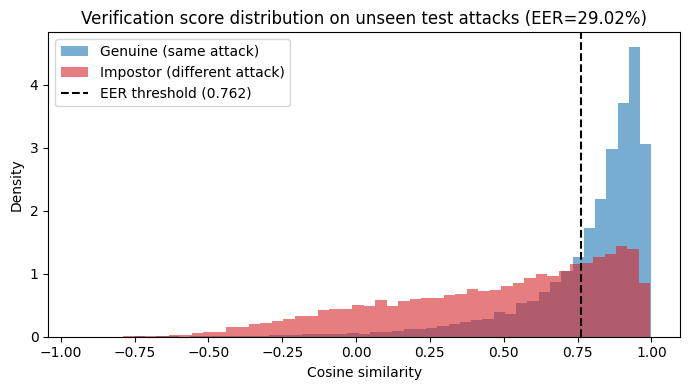

In [9]:
# Score distribution: genuine (same-attack) vs impostor (different-attack) pairs.
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.hist(pos_scores, bins=50, alpha=0.6, label="Genuine (same attack)", color="#1f77b4", density=True)
plt.hist(neg_scores, bins=50, alpha=0.6, label="Impostor (different attack)", color="#d62728", density=True)
plt.axvline(eer_threshold, color="black", linestyle="--", label=f"EER threshold ({eer_threshold:.3f})")
plt.xlabel("Cosine similarity")
plt.ylabel("Density")
plt.title(f"Verification score distribution on unseen test attacks (EER={eer*100:.2f}%)")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "verification_score_distribution.png"), dpi=150)
plt.show()


## 8. (Complementary view) Open-set clustering
A different lens on the same question: does the embedding space group unseen
generators into clean clusters, not just pairwise same/different?

In [10]:
def purity_score(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    total = 0
    for cluster_id in np.unique(y_pred):
        mask = y_pred == cluster_id
        if mask.sum() == 0:
            continue
        total += np.bincount(y_true[mask]).max()
    return total / len(y_true)


le = LabelEncoder()
true_labels = le.fit_transform(true_attacks)
n_true_clusters = len(le.classes_)
print(f"True unseen attack classes in test set: {list(le.classes_)} ({n_true_clusters} total)")

k = TEST_NUM_CLUSTERS or n_true_clusters
kmeans = KMeans(n_clusters=k, random_state=SEED, n_init=10)
pred_clusters = kmeans.fit_predict(embeddings)

nmi = normalized_mutual_info_score(true_labels, pred_clusters)
ari = adjusted_rand_score(true_labels, pred_clusters)
purity = purity_score(true_labels, pred_clusters)

print(f"Open-set clustering (K={k}) vs {n_true_clusters} true unseen attacks:")
print(f"  NMI: {nmi:.4f}  ARI: {ari:.4f}  Purity: {purity:.4f}")

with open(os.path.join(RESULTS_DIR, "test_clustering_eval.json"), "w") as f:
    json.dump({"nmi": nmi, "ari": ari, "purity": purity, "k": k,
               "n_true_unseen_classes": n_true_clusters}, f, indent=2)


True unseen attack classes in test set: [np.str_('A07'), np.str_('A08'), np.str_('A09'), np.str_('A10'), np.str_('A11'), np.str_('A12'), np.str_('A13'), np.str_('A14'), np.str_('A15'), np.str_('A16'), np.str_('A17'), np.str_('A18'), np.str_('A19')] (13 total)
Open-set clustering (K=13) vs 13 true unseen attacks:
  NMI: 0.4271  ARI: 0.2449  Purity: 0.4288


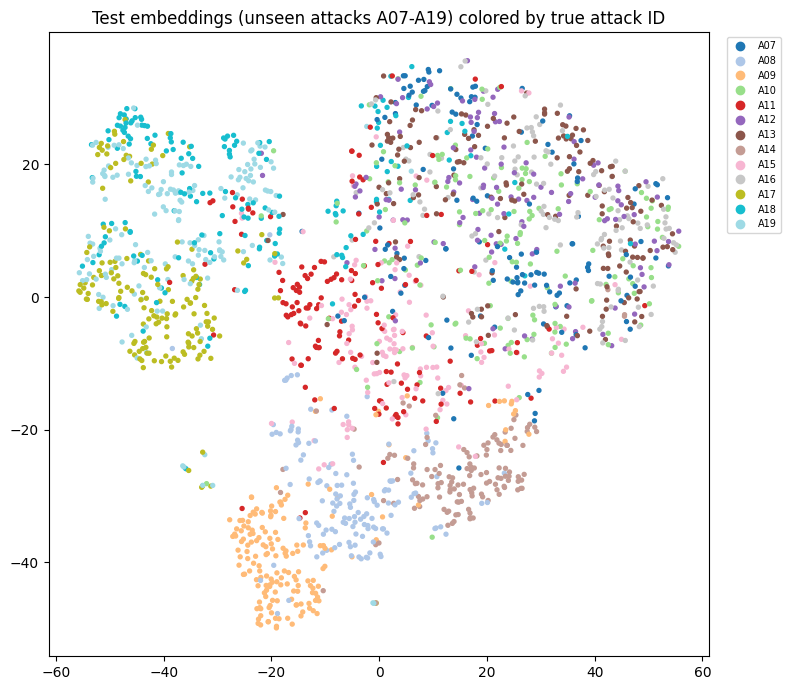

In [11]:
from sklearn.manifold import TSNE

n_plot = min(2000, embeddings.shape[0])
idx = np.random.RandomState(SEED).choice(embeddings.shape[0], n_plot, replace=False)
perplexity = min(30, max(5, n_plot // 4))
proj = TSNE(n_components=2, random_state=SEED, init="pca", perplexity=perplexity).fit_transform(embeddings[idx])

plt.figure(figsize=(8, 7))
scatter = plt.scatter(proj[:, 0], proj[:, 1], c=true_labels[idx], cmap="tab20", s=8)
plt.legend(handles=scatter.legend_elements(num=n_true_clusters)[0], labels=list(le.classes_),
           bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)
plt.title("Test embeddings (unseen attacks A07-A19) colored by true attack ID")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "test_embeddings_tsne.png"), dpi=150)
plt.show()
